<a href="https://colab.research.google.com/github/sadhyasora-bit/Fraud-Detection_Model/blob/main/notebook/03_Scenario_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. Imbalance Handling & Scenario Preparation

Notebook ini bertujuan membentuk tiga skenario dataset untuk eksperimen
pemodelan Credit Card Fraud Detection.

Tahapan yang dilakukan meliputi:

1. Import library.
2. Memuat dataset hasil preprocessing dari Notebook 02.
3. Audit fitur dan target.
4. Preprocessing dasar menggunakan RobustScaler.
5. Pembentukan Skenario 1: Original Dataset.
6. Pembentukan Skenario 2: Augmentation Dataset menggunakan SMOTE.
7. Pembentukan Skenario 3: log1p(Amount), RobustScaler, dan SMOTE.
8. Validasi seluruh dataset.
9. Penyimpanan dataset dan preprocessing artifacts.

SMOTE hanya diterapkan pada data training. Data validation dan testing
tetap mempertahankan distribusi kelas aslinya.

## 1. Import library

In [12]:
# Install imbalanced-learn
!pip install -q imbalanced-learn

# Data manipulation
import os
import json
import shutil
import joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.preprocessing import RobustScaler

# Imbalance handling
from imblearn.over_sampling import SMOTE

# Reproducibility
RANDOM_STATE = 42

print("Libraries successfully imported.")

Libraries successfully imported.


## 2. Load dataset hasil preprocessing

In [13]:
import os

# Project directory
project_dir = "/content/drive/MyDrive/SEMESTER 7/PEMBELAJARAN MESIN/Project"

# Check dataset folder
dataset_dir = os.path.join(project_dir, "dataset")

print("=== DATASET DIRECTORY ===")
print("Path:", dataset_dir)
print("Exists:", os.path.exists(dataset_dir))

if os.path.exists(dataset_dir):
    print("\nFiles and folders:")
    for item in os.listdir(dataset_dir):
        print(item)

=== DATASET DIRECTORY ===
Path: /content/drive/MyDrive/SEMESTER 7/PEMBELAJARAN MESIN/Project/dataset
Exists: True

Files and folders:
y_train.csv
X_test.csv
y_test.csv
X_train.csv
y_val.csv
X_val.csv
preprocessed_data.zip


In [14]:
# Define Google Drive dataset directory
input_dir = "/content/drive/MyDrive/SEMESTER 7/PEMBELAJARAN MESIN/Project/dataset"

# Load training, validation, and testing datasets
X_train = pd.read_csv(os.path.join(input_dir, "X_train.csv"))
y_train = pd.read_csv(os.path.join(input_dir, "y_train.csv")).squeeze("columns")

X_val = pd.read_csv(os.path.join(input_dir, "X_val.csv"))
y_val = pd.read_csv(os.path.join(input_dir, "y_val.csv")).squeeze("columns")

X_test = pd.read_csv(os.path.join(input_dir, "X_test.csv"))
y_test = pd.read_csv(os.path.join(input_dir, "y_test.csv")).squeeze("columns")

# Display dataset dimensions
print("=== DATASET DIMENSIONS ===")
print(f"X_train : {X_train.shape}")
print(f"y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape}")
print(f"y_val   : {y_val.shape}")
print(f"X_test  : {X_test.shape}")
print(f"y_test  : {y_test.shape}")

=== DATASET DIMENSIONS ===
X_train : (198608, 30)
y_train : (198608,)
X_val   : (42559, 30)
y_val   : (42559,)
X_test  : (42559, 30)
y_test  : (42559,)


## 3. Audit Fitur dan Target

In [15]:
# ==========================================
# FEATURE AND TARGET AUDIT
# ==========================================

print("===== FEATURE AND TARGET AUDIT =====")

# 1. Check feature-target separation
assert "Class" not in X_train.columns, \
    "Target Class ditemukan dalam X_train!"

assert "Class" not in X_val.columns, \
    "Target Class ditemukan dalam X_val!"

assert "Class" not in X_test.columns, \
    "Target Class ditemukan dalam X_test!"

# 2. Check feature consistency
assert list(X_train.columns) == list(X_val.columns), \
    "Kolom training dan validation tidak sama!"

assert list(X_train.columns) == list(X_test.columns), \
    "Kolom training dan testing tidak sama!"

# 3. Check dimensions
assert X_train.shape[1] == 30, \
    "Jumlah fitur tidak sesuai dengan dataset!"

# 4. Check target labels
assert set(y_train.unique()) == {0, 1}
assert set(y_val.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

# 5. Check missing values
assert X_train.isnull().sum().sum() == 0
assert X_val.isnull().sum().sum() == 0
assert X_test.isnull().sum().sum() == 0

# 6. Check infinite values
assert np.isfinite(X_train.select_dtypes(include=np.number)).all().all()
assert np.isfinite(X_val.select_dtypes(include=np.number)).all().all()
assert np.isfinite(X_test.select_dtypes(include=np.number)).all().all()

# 7. Check Amount
assert (X_train["Amount"] >= 0).all()
assert (X_val["Amount"] >= 0).all()
assert (X_test["Amount"] >= 0).all()

print("Feature count:", X_train.shape[1])
print("Feature-target separation: Valid")
print("Feature columns consistency: Valid")
print("Target labels: Valid")
print("Missing values: 0")
print("Infinite values: 0")
print("Amount non-negative: Valid")

print("\nFeature columns:")
print(X_train.columns.tolist())

print("\n===== AUDIT PASSED =====")

===== FEATURE AND TARGET AUDIT =====
Feature count: 30
Feature-target separation: Valid
Feature columns consistency: Valid
Target labels: Valid
Missing values: 0
Infinite values: 0
Amount non-negative: Valid

Feature columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

===== AUDIT PASSED =====


## 4. Distribusi Kelas Awal

In [16]:
# ==========================================
# ORIGINAL CLASS DISTRIBUTION
# ==========================================

class_distribution = pd.DataFrame({
    "Training": y_train.value_counts().sort_index(),
    "Validation": y_val.value_counts().sort_index(),
    "Testing": y_test.value_counts().sort_index()
})

class_distribution.index = ["Non-Fraud (0)", "Fraud (1)"]

display(class_distribution)

print("\nFraud percentage:")
for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    fraud_percentage = (target == 1).mean() * 100
    print(f"{name}: {fraud_percentage:.6f}%")

,Training,Validation,Testing
Non-Fraud (0),198277,42488,42488
Fraud (1),331,71,71



Fraud percentage:
Training: 0.166660%
Validation: 0.166827%
Testing: 0.166827%


## 5. Preprocessing Dasar: RobustScaler

In [17]:
# ==========================================
# BASE PREPROCESSING: ROBUST SCALER
# ==========================================

scaler_s1_s2 = RobustScaler()

# Fit and transform training data
X_train_scaled = pd.DataFrame(
    scaler_s1_s2.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Transform validation and testing
X_val_scaled = pd.DataFrame(
    scaler_s1_s2.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)

X_test_scaled = pd.DataFrame(
    scaler_s1_s2.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("===== ROBUST SCALER RESULTS =====")

print("Training   :", X_train_scaled.shape)
print("Validation :", X_val_scaled.shape)
print("Testing    :", X_test_scaled.shape)

print("\nTraining statistics:")
display(X_train_scaled.describe().T.round(4).head(10))

===== ROBUST SCALER RESULTS =====
Training   : (198608, 30)
Validation : (42559, 30)
Testing    : (42559, 30)

Training statistics:


,count,mean,std,min,25%,50%,75%,max
Time,198608.0,0.1182,0.5580,-0.9972,-0.3594,0.0,0.6406,1.0333
V1,198608.0,-0.0054,0.8728,-25.2904,-0.4182,-0.0,0.5818,1.0927
V2,198608.0,-0.0491,1.1744,-51.9194,-0.4736,0.0,0.5264,15.6893
V3,198608.0,-0.0917,0.7871,-17.6925,-0.5563,-0.0,0.4437,4.8099
V4,198608.0,0.0138,0.8908,-3.5532,-0.5194,0.0,0.4806,10.6050
V5,198608.0,0.0438,1.0421,-24.6016,-0.4887,0.0,0.5113,26.7620
V6,198608.0,0.2364,1.1363,-22.2035,-0.4220,-0.0,0.5780,18.5874
V7,198608.0,-0.0351,1.0657,-38.7622,-0.5277,0.0,0.4723,30.4616
V8,198608.0,-0.0416,2.1956,-136.9654,-0.4321,0.0,0.5679,36.5899
V9,198608.0,0.0397,0.8836,-10.7997,-0.4778,0.0,0.5222,12.6289


## 6. Pembentukan S1: Original Dataset

In [18]:
# ==========================================
# SCENARIO 1: ORIGINAL DATASET
# RobustScaler without SMOTE
# ==========================================

X_train_s1 = X_train_scaled.copy()
X_val_s1 = X_val_scaled.copy()
X_test_s1 = X_test_scaled.copy()

y_train_s1 = y_train.copy()
y_val_s1 = y_val.copy()
y_test_s1 = y_test.copy()

print("===== SCENARIO 1 =====")

print("\nTraining distribution:")
print(y_train_s1.value_counts().sort_index())

print("\nValidation distribution:")
print(y_val_s1.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test_s1.value_counts().sort_index())

print("\nDataset dimensions:")
print("Training   :", X_train_s1.shape)
print("Validation :", X_val_s1.shape)
print("Testing    :", X_test_s1.shape)

===== SCENARIO 1 =====

Training distribution:
Class
0    198277
1       331
Name: count, dtype: int64

Validation distribution:
Class
0    42488
1       71
Name: count, dtype: int64

Testing distribution:
Class
0    42488
1       71
Name: count, dtype: int64

Dataset dimensions:
Training   : (198608, 30)
Validation : (42559, 30)
Testing    : (42559, 30)


## 7. Pembentukan S2: RobustScaler + SMOTE

In [19]:
# ==========================================
# SCENARIO 2: AUGMENTATION DATASET
# RobustScaler + SMOTE
# ==========================================

smote_s2 = SMOTE(
    random_state=RANDOM_STATE,
    k_neighbors=5
)

X_train_s2_resampled, y_train_s2_resampled = smote_s2.fit_resample(
    X_train_scaled,
    y_train
)

# Convert to DataFrame and Series
X_train_s2 = pd.DataFrame(
    X_train_s2_resampled,
    columns=X_train.columns
)

y_train_s2 = pd.Series(
    y_train_s2_resampled,
    name="Class"
).astype(int)

# Validation and testing remain unchanged
X_val_s2 = X_val_scaled.copy()
X_test_s2 = X_test_scaled.copy()

y_val_s2 = y_val.copy()
y_test_s2 = y_test.copy()

print("===== SCENARIO 2 =====")

print("\nTraining distribution:")
print(y_train_s2.value_counts().sort_index())

print("\nValidation distribution:")
print(y_val_s2.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test_s2.value_counts().sort_index())

print("\nDataset dimensions:")
print("Training   :", X_train_s2.shape)
print("Validation :", X_val_s2.shape)
print("Testing    :", X_test_s2.shape)

===== SCENARIO 2 =====

Training distribution:
Class
0    198277
1    198277
Name: count, dtype: int64

Validation distribution:
Class
0    42488
1       71
Name: count, dtype: int64

Testing distribution:
Class
0    42488
1       71
Name: count, dtype: int64

Dataset dimensions:
Training   : (396554, 30)
Validation : (42559, 30)
Testing    : (42559, 30)


## 8. Pembentukan S3: log1p(Amount) + RobustScaler + SMOTE

In [20]:
# ==========================================
# SCENARIO 3:
# log1p(Amount) + RobustScaler + SMOTE
# ==========================================

# 1. Copy original split datasets
X_train_s3_raw = X_train.copy()
X_val_s3_raw = X_val.copy()
X_test_s3_raw = X_test.copy()

# 2. Validate Amount before log transformation
assert (X_train_s3_raw["Amount"] >= 0).all()
assert (X_val_s3_raw["Amount"] >= 0).all()
assert (X_test_s3_raw["Amount"] >= 0).all()

# 3. Apply log1p transformation to Amount
X_train_s3_raw["Amount"] = np.log1p(X_train_s3_raw["Amount"])
X_val_s3_raw["Amount"] = np.log1p(X_val_s3_raw["Amount"])
X_test_s3_raw["Amount"] = np.log1p(X_test_s3_raw["Amount"])

# 4. Fit RobustScaler only on training data
scaler_s3 = RobustScaler()

X_train_s3_scaled = pd.DataFrame(
    scaler_s3.fit_transform(X_train_s3_raw),
    columns=X_train_s3_raw.columns,
    index=X_train_s3_raw.index
)

X_val_s3_scaled = pd.DataFrame(
    scaler_s3.transform(X_val_s3_raw),
    columns=X_val_s3_raw.columns,
    index=X_val_s3_raw.index
)

X_test_s3_scaled = pd.DataFrame(
    scaler_s3.transform(X_test_s3_raw),
    columns=X_test_s3_raw.columns,
    index=X_test_s3_raw.index
)

# 5. Apply SMOTE only to training data
smote_s3 = SMOTE(
    random_state=RANDOM_STATE,
    k_neighbors=5
)

X_train_s3_resampled, y_train_s3_resampled = smote_s3.fit_resample(
    X_train_s3_scaled,
    y_train
)

# 6. Convert resampled data
X_train_s3 = pd.DataFrame(
    X_train_s3_resampled,
    columns=X_train.columns
)

y_train_s3 = pd.Series(
    y_train_s3_resampled,
    name="Class"
).astype(int)

# Validation and testing remain original in class distribution
X_val_s3 = X_val_s3_scaled.copy()
X_test_s3 = X_test_s3_scaled.copy()

y_val_s3 = y_val.copy()
y_test_s3 = y_test.copy()

print("===== SCENARIO 3 =====")

print("\nTraining distribution:")
print(y_train_s3.value_counts().sort_index())

print("\nValidation distribution:")
print(y_val_s3.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test_s3.value_counts().sort_index())

print("\nDataset dimensions:")
print("Training   :", X_train_s3.shape)
print("Validation :", X_val_s3.shape)
print("Testing    :", X_test_s3.shape)

print("\nAmount statistics after log1p and scaling:")
display(X_train_s3[["Amount"]].describe().round(4))

===== SCENARIO 3 =====

Training distribution:
Class
0    198277
1    198277
Name: count, dtype: int64

Validation distribution:
Class
0    42488
1       71
Name: count, dtype: int64

Testing distribution:
Class
0    42488
1       71
Name: count, dtype: int64

Dataset dimensions:
Training   : (396554, 30)
Validation : (42559, 30)
Testing    : (42559, 30)

Amount statistics after log1p and scaling:


,Amount
count,396554.0000
mean,-0.0866
std,0.7301
min,-1.2741
25%,-0.8282
50%,-0.1083
75%,0.5219
max,2.7230


## 9. Perbandingan Distribusi Kelas S1, S2, dan S3

,S1,S2,S3
Non-Fraud (0),198277,198277,198277
Fraud (1),331,198277,198277


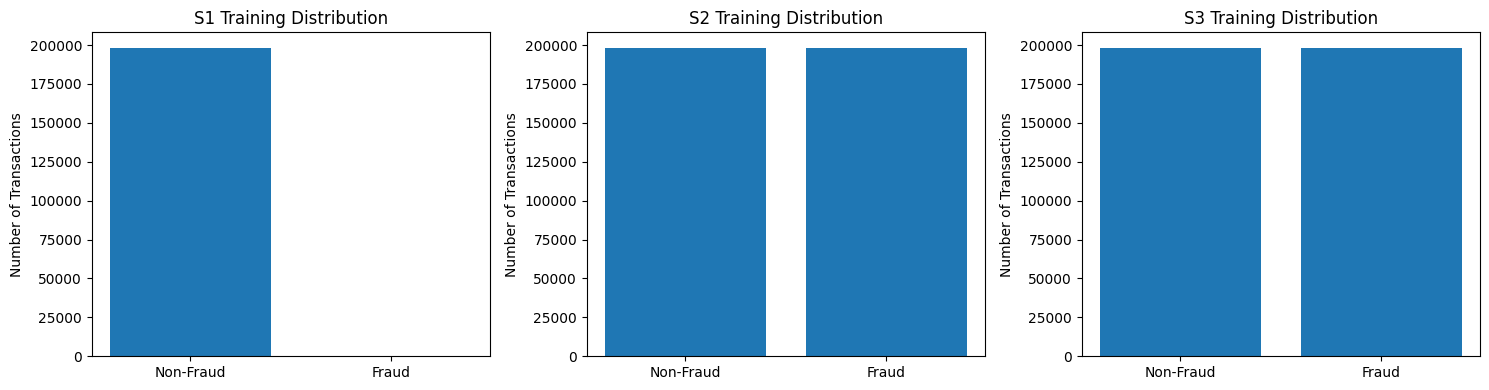

In [21]:
# ==========================================
# SCENARIO CLASS DISTRIBUTION COMPARISON
# ==========================================

scenario_targets = {
    "S1": y_train_s1,
    "S2": y_train_s2,
    "S3": y_train_s3
}

distribution_comparison = pd.DataFrame({
    name: target.value_counts().sort_index()
    for name, target in scenario_targets.items()
})

distribution_comparison.index = [
    "Non-Fraud (0)",
    "Fraud (1)"
]

display(distribution_comparison)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, target) in zip(axes, scenario_targets.items()):
    counts = target.value_counts().sort_index()

    ax.bar(
        ["Non-Fraud", "Fraud"],
        counts.values
    )

    ax.set_title(f"{name} Training Distribution")
    ax.set_ylabel("Number of Transactions")
    ax.ticklabel_format(axis="y", style="plain")

plt.tight_layout()
plt.show()

## 10. Validasi Seluruh Dataset

In [22]:
# ==========================================
# VALIDATION OF ALL SCENARIOS
# ==========================================

scenario_data = {
    "S1": {
        "X_train": X_train_s1,
        "y_train": y_train_s1,
        "X_val": X_val_s1,
        "y_val": y_val_s1,
        "X_test": X_test_s1,
        "y_test": y_test_s1
    },
    "S2": {
        "X_train": X_train_s2,
        "y_train": y_train_s2,
        "X_val": X_val_s2,
        "y_val": y_val_s2,
        "X_test": X_test_s2,
        "y_test": y_test_s2
    },
    "S3": {
        "X_train": X_train_s3,
        "y_train": y_train_s3,
        "X_val": X_val_s3,
        "y_val": y_val_s3,
        "X_test": X_test_s3,
        "y_test": y_test_s3
    }
}

validation_results = []

for scenario_name, data in scenario_data.items():

    for subset in ["train", "val", "test"]:

        X_data = data[f"X_{subset}"]
        y_data = data[f"y_{subset}"]

        # Check dimensions
        assert len(X_data) == len(y_data)

        # Check feature columns
        assert list(X_data.columns) == list(X_train.columns)

        # Check missing values
        assert X_data.isnull().sum().sum() == 0

        # Check infinite values
        assert np.isfinite(
            X_data.select_dtypes(include=np.number)
        ).all().all()

        # Check target labels
        assert set(y_data.unique()) == {0, 1}

        validation_results.append({
            "Scenario": scenario_name,
            "Subset": subset,
            "Rows": len(X_data),
            "Features": X_data.shape[1],
            "Non-Fraud": int((y_data == 0).sum()),
            "Fraud": int((y_data == 1).sum()),
            "Missing": int(X_data.isnull().sum().sum()),
            "Infinite": int(
                np.isinf(
                    X_data.select_dtypes(include=np.number)
                ).sum().sum()
            ),
            "Status": "PASS"
        })

validation_summary = pd.DataFrame(validation_results)

display(validation_summary)

print("\n===== ALL SCENARIO VALIDATIONS PASSED =====")

,Scenario,Subset,Rows,Features,Non-Fraud,Fraud,Missing,Infinite,Status
0,S1,train,198608,30,198277,331,0,0,PASS
1,S1,val,42559,30,42488,71,0,0,PASS
2,S1,test,42559,30,42488,71,0,0,PASS
3,S2,train,396554,30,198277,198277,0,0,PASS
4,S2,val,42559,30,42488,71,0,0,PASS
5,S2,test,42559,30,42488,71,0,0,PASS
6,S3,train,396554,30,198277,198277,0,0,PASS
7,S3,val,42559,30,42488,71,0,0,PASS
8,S3,test,42559,30,42488,71,0,0,PASS



===== ALL SCENARIO VALIDATIONS PASSED =====


## 11. Validasi Khusus Distribusi Validation dan Testing



In [23]:
# ==========================================
# VALIDATE ORIGINAL VALIDATION AND TEST SETS
# ==========================================

for scenario_name, data in scenario_data.items():

    assert data["y_val"].value_counts().sort_index().equals(
        y_val.value_counts().sort_index()
    )

    assert data["y_test"].value_counts().sort_index().equals(
        y_test.value_counts().sort_index()
    )

    assert len(data["X_val"]) == len(X_val)
    assert len(data["X_test"]) == len(X_test)

print("Validation class distributions remain unchanged.")
print("Testing class distributions remain unchanged.")

print("\nOriginal validation:", y_val.value_counts().to_dict())
print("Original testing   :", y_test.value_counts().to_dict())

Validation class distributions remain unchanged.
Testing class distributions remain unchanged.

Original validation: {0: 42488, 1: 71}
Original testing   : {0: 42488, 1: 71}


## 12. Simpan Dataset S1, S2, S3

In [24]:
# ==========================================
# SAVE SCENARIO DATASETS
# ==========================================

scenario_output_dir = "/content/scenario_data"

scenario_folder_names = {
    "S1": "S1_Original",
    "S2": "S2_Augmentation",
    "S3": "S3_Preprocessing_Augmentation"
}

os.makedirs(scenario_output_dir, exist_ok=True)

for scenario_name, data in scenario_data.items():

    folder_name = scenario_folder_names[scenario_name]

    output_folder = os.path.join(
        scenario_output_dir,
        folder_name
    )

    os.makedirs(output_folder, exist_ok=True)

    # Save feature datasets
    for subset in ["train", "val", "test"]:

        data[f"X_{subset}"].to_csv(
            os.path.join(output_folder, f"X_{subset}.csv"),
            index=False
        )

    # Save target datasets
    for subset in ["train", "val", "test"]:

        data[f"y_{subset}"].to_frame(name="Class").to_csv(
            os.path.join(output_folder, f"y_{subset}.csv"),
            index=False
        )

    print(f"{scenario_name} datasets saved to: {output_folder}")

print("\nAll scenario datasets saved successfully.")

S1 datasets saved to: /content/scenario_data/S1_Original
S2 datasets saved to: /content/scenario_data/S2_Augmentation
S3 datasets saved to: /content/scenario_data/S3_Preprocessing_Augmentation

All scenario datasets saved successfully.


## 13. Simpan Preprocessing Artifacts

In [25]:
# ==========================================
# SAVE PREPROCESSING ARTIFACTS
# ==========================================

artifact_dir = "/content/artifacts"

os.makedirs(artifact_dir, exist_ok=True)

# S1 and S2 use the same scaler
joblib.dump(
    scaler_s1_s2,
    os.path.join(artifact_dir, "scaler_s1_s2.joblib")
)

# S3 uses a separate scaler
joblib.dump(
    scaler_s3,
    os.path.join(artifact_dir, "scaler_s3.joblib")
)

print("Preprocessing artifacts saved.")

print("\nArtifact files:")
for filename in os.listdir(artifact_dir):
    print("-", filename)

Preprocessing artifacts saved.

Artifact files:
- scaler_s1_s2.joblib
- scaler_s3.joblib


## 14. Simpan Metadata Skenario

In [26]:
# ==========================================
# SAVE SCENARIO METADATA
# ==========================================

scenario_metadata = {
    "dataset": "European Credit Card Fraud Detection",
    "random_state": RANDOM_STATE,

    "base_split": {
        "training": 0.70,
        "validation": 0.15,
        "testing": 0.15
    },

    "target": "Class",
    "target_mapping": {
        "0": "Non-Fraud",
        "1": "Fraud"
    },

    "features": list(X_train.columns),

    "scenarios": {
        "S1": {
            "name": "Original Dataset",
            "scaling": "RobustScaler",
            "log1p_amount": False,
            "smote": False,
            "training_distribution": {
                str(k): int(v)
                for k, v in y_train_s1.value_counts().items()
            },
            "scaler_artifact": "scaler_s1_s2.joblib"
        },

        "S2": {
            "name": "Augmentation Dataset",
            "scaling": "RobustScaler",
            "log1p_amount": False,
            "smote": True,
            "smote_applied_to": "Training only",
            "training_distribution": {
                str(k): int(v)
                for k, v in y_train_s2.value_counts().items()
            },
            "scaler_artifact": "scaler_s1_s2.joblib"
        },

        "S3": {
            "name": "Preprocessing and Augmentation Dataset",
            "feature_transformation": {
                "Amount": "log1p"
            },
            "scaling": "RobustScaler",
            "smote": True,
            "smote_applied_to": "Training only",
            "training_distribution": {
                str(k): int(v)
                for k, v in y_train_s3.value_counts().items()
            },
            "scaler_artifact": "scaler_s3.joblib"
        }
    },

    "validation_testing": {
        "smote_applied": False,
        "class_distribution_preserved": True
    }
}

metadata_path = os.path.join(
    artifact_dir,
    "scenario_metadata.json"
)

with open(metadata_path, "w") as file:
    json.dump(scenario_metadata, file, indent=4)

print("Scenario metadata saved:")
print(metadata_path)

Scenario metadata saved:
/content/artifacts/scenario_metadata.json


## 15. ZIP Seluruh Output

In [27]:
# ==========================================
# PACKAGE ALL OUTPUTS
# ==========================================

package_dir = "/content/final_scenario_outputs"

os.makedirs(package_dir, exist_ok=True)

# Copy scenario datasets
shutil.copytree(
    scenario_output_dir,
    os.path.join(package_dir, "scenarios"),
    dirs_exist_ok=True
)

# Copy artifacts
shutil.copytree(
    artifact_dir,
    os.path.join(package_dir, "artifacts"),
    dirs_exist_ok=True
)

# Create ZIP
zip_path = shutil.make_archive(
    "/content/final_scenario_outputs",
    "zip",
    package_dir
)

print("ZIP successfully created:")
print(zip_path)

ZIP successfully created:
/content/final_scenario_outputs.zip


In [28]:
from google.colab import files

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Ringkasan Output

In [ ]:
# ==========================================
# FINAL OUTPUT SUMMARY
# ==========================================

print("===== FINAL SCENARIO SUMMARY =====")

for scenario_name, data in scenario_data.items():

    print(f"\n{scenario_name}")

    for subset in ["train", "val", "test"]:

        X_data = data[f"X_{subset}"]
        y_data = data[f"y_{subset}"]

        print(
            f"{subset.upper():5} | "
            f"X: {X_data.shape} | "
            f"y: {y_data.shape} | "
            f"Class: {y_data.value_counts().sort_index().to_dict()}"
        )

print("\n===== OUTPUT FILES =====")

for root, dirs, files_list in os.walk(package_dir):
    for filename in files_list:
        print(os.path.relpath(
            os.path.join(root, filename),
            package_dir
        ))

print("\nNotebook 03 completed successfully.")